# 4. Feature Selection & PCA Analysis

---

### Objectives:
1. **Filter-Based Selection**: Random Forest Feature Importance (Gini-based) — uses concepts from Decision Trees.
2. **Wrapper-Based Selection**: Recursive Feature Elimination (**RFE**) with Random Forest.
3. **Unsupervised Compression**: Principal Component Analysis (**PCA**) retaining 95% total variance.
4. **Comparative Analysis**: Trade-off between accuracy, model complexity, and feature dimensionality.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_selection import RFE
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

warnings.filterwarnings('ignore')
os.makedirs('../models', exist_ok=True)
os.makedirs('../presentation', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

# Ingest clean data
X_train, y_train, X_test, y_test = joblib.load('../data/processed_data.pkl')
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Baseline Feature Dimension: {X_train.shape[1]} features across {len(X_train)} samples")

Baseline Feature Dimension: 562 features across 7352 samples


## 1. Filter Selection: Random Forest Feature Importance (Gini-based)

In [2]:
# Random Forest importance — based on Gini impurity reduction (Decision Tree concept)
rf_imp = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_imp.fit(X_train_scaled, y_train_enc)

# Get top 100 features by importance
top_100_idx = np.argsort(rf_imp.feature_importances_)[::-1][:100]
X_train_fs = X_train_scaled[:, top_100_idx]
X_test_fs = X_test_scaled[:, top_100_idx]

# Evaluate with benchmark classifier
benchmark_clf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
score_fs = cross_val_score(benchmark_clf, X_train_fs, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()
print(f"Random Forest Importance (Top 100): CV Acc = {score_fs*100:.2f}%")

# Also test k = 50, 150, 200, 300 for curve
k_values = [50, 100, 150, 200, 300]
fs_scores = []

for k in k_values:
    idx = np.argsort(rf_imp.feature_importances_)[::-1][:k]
    X_sub = X_train_scaled[:, idx]
    score = cross_val_score(benchmark_clf, X_sub, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()
    fs_scores.append(score)
    print(f"  k = {k:3d} | CV Acc = {score*100:.2f}%")

Random Forest Importance (Top 100): CV Acc = 98.07%


  k =  50 | CV Acc = 98.11%


  k = 100 | CV Acc = 98.07%


  k = 150 | CV Acc = 98.04%


  k = 200 | CV Acc = 98.18%


  k = 300 | CV Acc = 98.27%


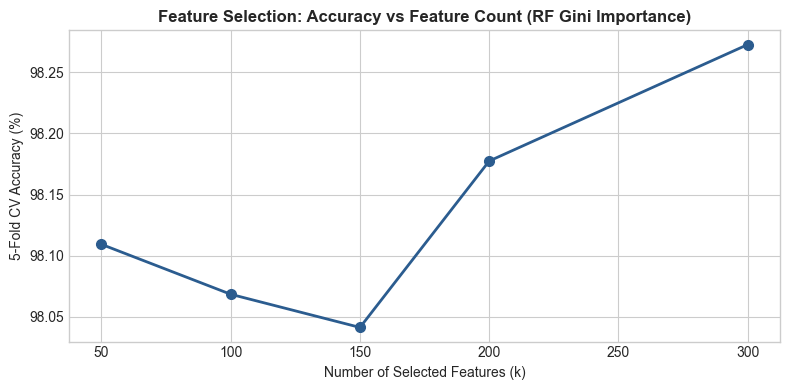

In [3]:
# Plot Feature Importance curve
plt.figure(figsize=(8, 4))
plt.plot(k_values, [s*100 for s in fs_scores], 'o-', color='#2b5c8f', linewidth=2, markersize=7)
plt.title('Feature Selection: Accuracy vs Feature Count (RF Gini Importance)', fontweight='bold')
plt.xlabel('Number of Selected Features (k)')
plt.ylabel('5-Fold CV Accuracy (%)')
plt.grid(True)
plt.tight_layout()
plt.savefig('../presentation/11_rf_importance_curve.png', dpi=200)
plt.show()

## 2. Wrapper Selection: RFE (Recursive Feature Elimination)

In [4]:
# RFE with Random Forest
rfe_features = [50, 100, 150, 200, 300]
rfe_scores = []

for n_feat in rfe_features:
    rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    rfe = RFE(rf, n_features_to_select=n_feat, step=50)
    X_train_rfe = rfe.fit_transform(X_train_scaled, y_train_enc)
    
    score = cross_val_score(rf, X_train_rfe, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()
    rfe_scores.append(score)
    print(f"RFE n={n_feat} | CV Acc = {score*100:.2f}%")

RFE n=50 | CV Acc = 97.81%


RFE n=100 | CV Acc = 98.33%


RFE n=150 | CV Acc = 98.31%


RFE n=200 | CV Acc = 98.23%


RFE n=300 | CV Acc = 98.11%


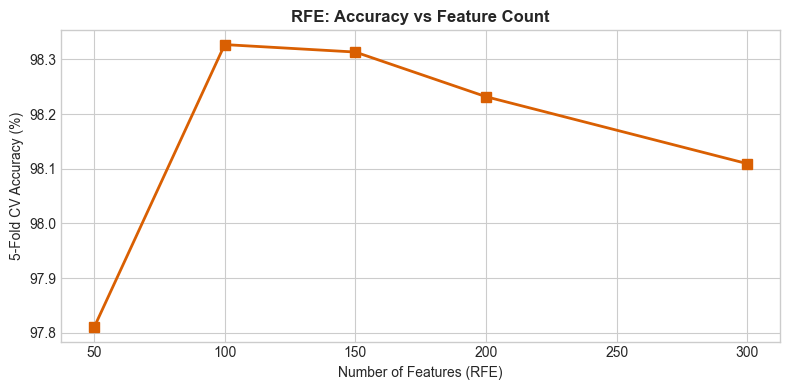

In [5]:
# Plot RFE curve
plt.figure(figsize=(8, 4))
plt.plot(rfe_features, [s*100 for s in rfe_scores], 's-', color='#d95f02', linewidth=2, markersize=7)
plt.title('RFE: Accuracy vs Feature Count', fontweight='bold')
plt.xlabel('Number of Features (RFE)')
plt.ylabel('5-Fold CV Accuracy (%)')
plt.grid(True)
plt.tight_layout()
plt.savefig('../presentation/11b_rfe_curve.png', dpi=200)
plt.show()

## 3. PCA Dimensionality Reduction: 95% Variance Threshold

In [6]:
# Retain 95% of cumulative explained variance
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_95.fit_transform(X_train_scaled)
X_test_pca = pca_95.transform(X_test_scaled)

n_components_ = pca_95.n_components_
reduction_pct = (1 - n_components_ / X_train.shape[1]) * 100

print(f"Original Dimension     : {X_train.shape[1]} features")
print(f"Compressed Dimension   : {n_components_} components")
print(f"Dimensionality Reduced : {reduction_pct:.2f}% reduction!")
print(f"Retained Variance      : {pca_95.explained_variance_ratio_.sum()*100:.2f}%")

# Evaluate SVM on PCA space
svm_pca = SVC(kernel='rbf', C=10.0, random_state=42)
pca_score = cross_val_score(svm_pca, X_train_pca, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()
print(f"SVM on PCA ({n_components_} PCs) CV Accuracy: {pca_score*100:.2f}%")

Original Dimension     : 562 features
Compressed Dimension   : 102 components
Dimensionality Reduced : 81.85% reduction!
Retained Variance      : 95.01%


SVM on PCA (102 PCs) CV Accuracy: 97.74%


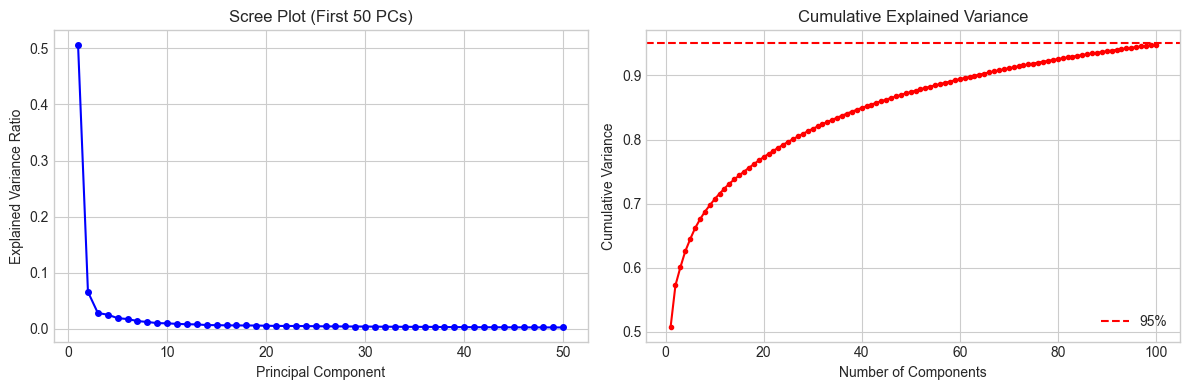

In [7]:
# PCA Scree & Cumulative Variance plots
explained_var = pca_95.explained_variance_ratio_
cumsum_var = np.cumsum(explained_var)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 51), explained_var[:50], 'bo-', markersize=4)
axes[0].set_title('Scree Plot (First 50 PCs)')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].grid(True)

axes[1].plot(range(1, 101), cumsum_var[:100], 'ro-', markersize=3)
axes[1].axhline(0.95, color='red', linestyle='--', label='95%')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('../presentation/12_pca_analysis.png', dpi=200)
plt.show()

## 4. Triple Comparison: All Features vs RF Importance vs PCA

           Approach  Features Count  CV Accuracy (%)
       All Features             561        98.843806
RF Importance (100)             100        98.068453
      PCA (102 PCs)             102        97.742033


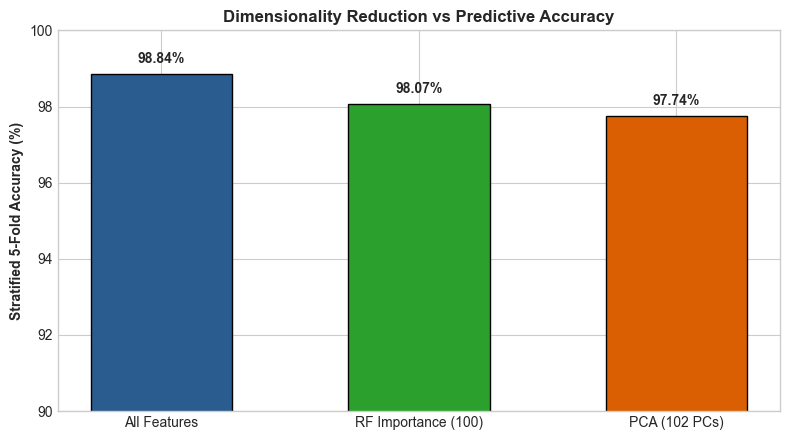

In [8]:
# Quick evaluation with standard SVM
svm = SVC(kernel='rbf', C=10.0, random_state=42)

# 1. All Features (561)
acc_all = cross_val_score(svm, X_train_scaled, y_train_enc, cv=cv, scoring='accuracy', n_jobs=-1).mean()

# 2. RF Importance (100)
acc_fs = score_fs

# 3. PCA (~102 components for 95% var)
acc_pca = pca_score

comparison_df = pd.DataFrame({
    'Approach': ['All Features', 'RF Importance (100)', f'PCA ({n_components_} PCs)'],
    'Features Count': [561, 100, n_components_],
    'CV Accuracy (%)': [acc_all*100, acc_fs*100, acc_pca*100]
})
print(comparison_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(comparison_df['Approach'], comparison_df['CV Accuracy (%)'], 
              color=['#2b5c8f', '#2ca02c', '#d95f02'], edgecolor='black', width=0.55)
ax.set_ylim(90, 100)
ax.set_ylabel('Stratified 5-Fold Accuracy (%)', fontweight='bold')
ax.set_title('Dimensionality Reduction vs Predictive Accuracy', fontweight='bold')
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3, f"{b.get_height():.2f}%", 
            ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../presentation/13_feature_selection_vs_pca.png', dpi=200)
plt.show()

In [9]:
# Persist artifacts
joblib.dump({
    'rf_imp': rf_imp,
    'top_100_idx': top_100_idx,
    'pca_95': pca_95,
    'comparison_df': comparison_df
}, '../models/fs_pca_results.pkl')
print('Artifacts saved to ../models/fs_pca_results.pkl')

Artifacts saved to ../models/fs_pca_results.pkl


## 5. Logistic Regression: All Features vs RF Importance vs RFE vs PCA

In [ ]:
# Logistic Regression comparison with preprocessing fitted inside each CV fold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

lr_models = {
    'All Features': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
    'RF Importance (100)': make_pipeline(StandardScaler(), SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1), threshold=-np.inf, max_features=100), LogisticRegression(max_iter=2000, random_state=42)),
    'RFE (100)': make_pipeline(StandardScaler(), RFE(RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=1), n_features_to_select=100, step=50), LogisticRegression(max_iter=2000, random_state=42)),
    'PCA (95% variance)': make_pipeline(StandardScaler(), PCA(n_components=0.95), LogisticRegression(max_iter=2000, random_state=42))
}
lr_rows = []
for name, model in lr_models.items():
    scores = cross_val_score(model, X_train, y_train_enc, cv=cv, scoring='accuracy', n_jobs=1)
    model.fit(X_train, y_train_enc)
    pred = model.predict(X_test)
    lr_rows.append({'Approach': name, 'CV Accuracy (%)': scores.mean()*100,
                    'CV Std (%)': scores.std()*100, 'Test Accuracy (%)': accuracy_score(y_test_enc, pred)*100,
                    'Precision (%)': precision_score(y_test_enc, pred, average='macro', zero_division=0)*100,
                    'Recall (%)': recall_score(y_test_enc, pred, average='macro', zero_division=0)*100,
                    'F1 (%)': f1_score(y_test_enc, pred, average='macro', zero_division=0)*100})
lr_comparison = pd.DataFrame(lr_rows)
print(lr_comparison.to_string(index=False))
lr_comparison.set_index('Approach')[['CV Accuracy (%)', 'Test Accuracy (%)']].plot.bar(figsize=(10, 5), rot=15)
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig('../presentation/logistic_regression_feature_comparison.png', dpi=200)
plt.show()
joblib.dump({'models': lr_models, 'comparison': lr_comparison, 'label_encoder': le}, '../models/logistic_regression_features.pkl')


## Saved graph previews
Historical feature-selection and PCA plots (from earlier runs):

![RF importance](../presentation/11_rf_importance_curve.png)

![RFE](../presentation/11b_rfe_curve.png)

![PCA](../presentation/12_pca_analysis.png)

![Feature comparison](../presentation/13_feature_selection_vs_pca.png)

### Recorded Logistic Regression comparison
![LR comparison](../presentation/logistic_regression_feature_comparison.svg)

LR RFE results are pending.